# Day 3 — Customer Feedback Analysis Using NLP




## 1. Imports and paths

In [1]:
from pathlib import Path
import re, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix, ConfusionMatrixDisplay
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW=ROOT/"data/raw"; PROCESSED=ROOT/"data/processed"; OUT=ROOT/"outputs/nlp_sentiment"; MODELS=ROOT/"models"
for p in [PROCESSED, OUT, MODELS]: p.mkdir(parents=True, exist_ok=True)
reviews=pd.read_csv(RAW/"reviews.csv", parse_dates=["review_timestamp"])
print(reviews.shape); display(reviews.head())

(1147, 6)


,review_id,order_id,customer_id,rating,review_text,review_timestamp
0,REV00001,ORD00002,CUST0194,5,Quick delivery and friendly driver.,2026-02-09 19:41:00
1,REV00002,ORD00003,CUST0264,5,Food arrived hot and tasted great.,2026-02-23 21:24:00
2,REV00003,ORD00004,CUST0194,4,Food arrived hot and tasted great.,2026-02-21 08:38:00
3,REV00004,ORD00005,CUST0114,4,Quick delivery and friendly driver.,2026-01-12 12:50:00
4,REV00005,ORD00006,CUST0124,2,Order was missing an item.,2026-03-11 15:21:00


## 2. Create sentiment labels and clean text
Lowercase, tokenize, remove punctuation and stop words, and lemmatize where WordNet is available. Negation words are preserved because they affect sentiment.

In [2]:
reviews=reviews.dropna(subset=["review_text","rating"]).copy()
reviews["sentiment"]=np.select([reviews.rating>=4, reviews.rating<=2],["positive","negative"],default="neutral")
STOP=set(ENGLISH_STOP_WORDS)-{"not","no","nor","never"}
try:
 import nltk
 from nltk.stem import WordNetLemmatizer
 _lem=WordNetLemmatizer(); _lem.lemmatize("orders"); WORDNET=True
except Exception:
 WORDNET=False
def clean_text(text):
 tokens=re.findall(r"[a-z]+", str(text).lower())
 tokens=[t for t in tokens if t not in STOP]
 if WORDNET: tokens=[_lem.lemmatize(t) for t in tokens]
 else: tokens=[t[:-3] if t.endswith("ing") and len(t)>5 else t for t in tokens]
 return " ".join(tokens)
reviews["clean_review"]=reviews.review_text.apply(clean_text)
print("WordNet lemmatization available:",WORDNET); display(reviews[["review_text","clean_review","rating","sentiment"]].head())
display(reviews.sentiment.value_counts().to_frame("review_count"))

WordNet lemmatization available: False


,review_text,clean_review,rating,sentiment
0,Quick delivery and friendly driver.,quick delivery friendly driver,5,positive
1,Food arrived hot and tasted great.,food arrived hot tasted great,5,positive
2,Food arrived hot and tasted great.,food arrived hot tasted great,4,positive
3,Quick delivery and friendly driver.,quick delivery friendly driver,4,positive
4,Order was missing an item.,order miss item,2,negative


,review_count
sentiment,
positive,686
neutral,327
negative,134


## 3. TF-IDF features and important words/phrases
Use unigrams and bigrams. Fit the vectorizer on training text only to avoid test-data leakage.

In [3]:
X_train,X_test,y_train,y_test,idx_train,idx_test=train_test_split(reviews.clean_review,reviews.sentiment,reviews.index,test_size=.25,random_state=42,stratify=reviews.sentiment if reviews.sentiment.value_counts().min()>=2 else None)
tfidf=TfidfVectorizer(ngram_range=(1,2),max_features=3000,min_df=1)
Xtr=tfidf.fit_transform(X_train); Xte=tfidf.transform(X_test)
terms=np.array(tfidf.get_feature_names_out()); means=np.asarray(Xtr.mean(axis=0)).ravel(); ix=means.argsort()[::-1][:20]
top_terms=pd.DataFrame({"term_or_phrase":terms[ix],"mean_tfidf":means[ix]}); display(top_terms)
top_terms.to_csv(OUT/"top_tfidf_terms.csv",index=False)
for lab in ["positive","negative"]:
 text=reviews.loc[idx_train][reviews.loc[idx_train,"sentiment"]==lab].clean_review
 if len(text):
  v=TfidfVectorizer(ngram_range=(1,2),max_features=1500); mat=v.fit_transform(text); m=np.asarray(mat.mean(axis=0)).ravel(); j=m.argsort()[::-1][:12]
  print("Top",lab,"terms:"); display(pd.DataFrame({"term":v.get_feature_names_out()[j],"mean_tfidf":m[j]}))

,term_or_phrase,mean_tfidf
0,food,0.100965
1,order,0.092418
2,delivery,0.084610
3,friendly driver,0.064120
4,friendly,0.064120
5,quick,0.064120
6,quick delivery,0.064120
7,delivery friendly,0.064120
8,driver,0.064120
9,fresh food,0.062763


Top positive terms:


,term,mean_tfidf
0,food,0.129535
1,quick,0.104418
2,driver,0.104418
3,friendly driver,0.104418
4,quick delivery,0.104418
5,friendly,0.104418
6,delivery,0.104418
7,delivery friendly,0.104418
8,fresh,0.101265
9,fresh food,0.101265


Top negative terms:


,term,mean_tfidf
0,food,0.158695
1,delivery late,0.119708
2,cold,0.119708
3,late food,0.119708
4,food cold,0.119708
5,late,0.119708
6,delivery,0.119708
7,damaged,0.116009
8,support,0.116009
9,packag damaged,0.116009


## 4. Train Naive Bayes and evaluate
Metrics are compared against rating-derived sentiment labels, not independent human annotations.

,model,accuracy,weighted_precision,weighted_recall,weighted_f1
0,TF-IDF + MultinomialNB,1.0,1.0,1.0,1.0


              precision    recall  f1-score   support

    negative       1.00      1.00      1.00        33
     neutral       1.00      1.00      1.00        82
    positive       1.00      1.00      1.00       172

    accuracy                           1.00       287
   macro avg       1.00      1.00      1.00       287
weighted avg       1.00      1.00      1.00       287



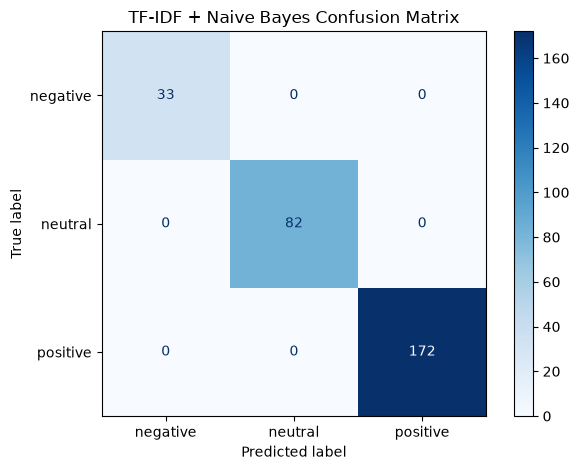

In [4]:
model=MultinomialNB(); model.fit(Xtr,y_train); pred=model.predict(Xte)
p,r,f1,_=precision_recall_fscore_support(y_test,pred,average="weighted",zero_division=0)
metrics=pd.DataFrame([{"model":"TF-IDF + MultinomialNB","accuracy":accuracy_score(y_test,pred),"weighted_precision":p,"weighted_recall":r,"weighted_f1":f1}])
display(metrics.round(3)); print(classification_report(y_test,pred,zero_division=0))
metrics.to_csv(OUT/"sentiment_model_metrics.csv",index=False); joblib.dump(model,MODELS/"review_sentiment_naive_bayes.joblib"); joblib.dump(tfidf,MODELS/"review_tfidf_vectorizer.joblib")
labels=["negative","neutral","positive"]; disp=ConfusionMatrixDisplay(confusion_matrix(y_test,pred,labels=labels),display_labels=labels); disp.plot(cmap="Blues",values_format="d")
plt.title("TF-IDF + Naive Bayes Confusion Matrix"); plt.tight_layout(); plt.savefig(OUT/"sentiment_confusion_matrix.png",dpi=150); plt.show()

## 5. VADER comparison
VADER is designed for short text and considers punctuation, capitalization and some emoji/slang patterns. It scores original review text, not the cleaned version.

In [5]:
try:
 from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
 vader=SentimentIntensityAnalyzer(); vader_available=True
except ImportError:
 vader_available=False; print("VADER is unavailable. Install requirements with: python -m pip install -r requirements.txt")
if vader_available:
 def vader_label(text):
  c=vader.polarity_scores(str(text))["compound"]
  return "positive" if c>=.05 else ("negative" if c<=-.05 else "neutral")
 reviews["vader_compound"]=reviews.review_text.apply(lambda t:vader.polarity_scores(str(t))["compound"])
 reviews["vader_sentiment"]=reviews.review_text.apply(vader_label)
 vp,vr,vf,_=precision_recall_fscore_support(reviews.sentiment,reviews.vader_sentiment,average="weighted",zero_division=0)
 vader_metrics=pd.DataFrame([{"model":"VADER (original text)","accuracy":accuracy_score(reviews.sentiment,reviews.vader_sentiment),"weighted_precision":vp,"weighted_recall":vr,"weighted_f1":vf}])
 comparison=pd.concat([metrics,vader_metrics],ignore_index=True); display(comparison.round(3)); comparison.to_csv(OUT/"sentiment_model_comparison.csv",index=False)
else:
 comparison=metrics.copy(); comparison.to_csv(OUT/"sentiment_model_comparison.csv",index=False)

VADER is unavailable. Install requirements with: python -m pip install -r requirements.txt


## 6. Complaint themes and exports
Top terms in negative-labelled reviews are exploratory complaint signals. Inspect actual examples before claiming a definitive cause.

In [6]:
negative=reviews[reviews.sentiment=="negative"].copy(); print("Negative reviews:",len(negative),"of",len(reviews))
if len(negative):
 v=TfidfVectorizer(ngram_range=(1,2),max_features=1000,min_df=1); mat=v.fit_transform(negative.clean_review); means=np.asarray(mat.mean(axis=0)).ravel(); ids=means.argsort()[::-1][:20]
 complaints=pd.DataFrame({"term_or_phrase":v.get_feature_names_out()[ids],"mean_tfidf":means[ids]}); display(complaints); complaints.to_csv(OUT/"top_negative_review_terms.csv",index=False)
 display(negative[["rating","review_text"]].head(15))
summary=reviews.groupby("sentiment").agg(review_count=("review_id","count"),average_rating=("rating","mean")).round(2); summary["share_percent"]=(summary.review_count/len(reviews)*100).round(1); display(summary); summary.to_csv(OUT/"sentiment_insights.csv")
cols=["review_id","order_id","customer_id","rating","review_text","review_timestamp","sentiment","clean_review"]
for c in ["vader_compound","vader_sentiment"]:
 if c in reviews: cols.append(c)
reviews[cols].to_csv(PROCESSED/"cleaned_reviews_sentiment.csv",index=False)
print("Saved cleaned reviews, sentiment metrics, confusion matrix, TF-IDF terms and complaint themes.")

Negative reviews: 134 of 1147


,term_or_phrase,mean_tfidf
0,food,0.153105
1,quality,0.112702
2,quality disappoint,0.112702
3,food quality,0.112702
4,disappoint,0.112702
5,slow,0.104363
6,support slow,0.104363
7,packag,0.104363
8,packag damaged,0.104363
9,support,0.104363


,rating,review_text
4,2,Order was missing an item.
5,2,Delivery was late and the food was cold.
10,2,Food quality was disappointing.
15,2,Packaging was damaged and support was slow.
26,2,Order was missing an item.
39,2,Food quality was disappointing.
54,2,Delivery was late and the food was cold.
58,1,Packaging was damaged and support was slow.
66,2,Food quality was disappointing.
85,2,Packaging was damaged and support was slow.


,review_count,average_rating,share_percent
sentiment,,,
negative,134,1.87,11.7
neutral,327,3.00,28.5
positive,686,4.33,59.8


Saved cleaned reviews, sentiment metrics, confusion matrix, TF-IDF terms and complaint themes.
